# manasight 04: CLIP zero-shot

**Hypothesis H3:** a pretrained model that has never seen our labels already knows the game's themes.

**CLIP** was trained on hundreds of millions of pictures with their captions from the web. It turns a picture and a
sentence into the same kind of numbers, so we can ask "which of these sentences fits this picture best?".
That is **zero-shot** classification: write one or more sentences ("prompts") per class and pick the closest.
Nothing is trained here.

The experiment is in the prompts. Five ways to describe a color:

| Prompts | Example for Red | What it tests |
|---|---|---|
| Naive | "a red Magic: The Gathering card" | Does CLIP know the game by name? |
| Palette | "a painting in warm red and orange tones" | The palette idea, in words |
| Content (hand-written) | "a fantasy painting of goblins", "... of fire" | Content, guided by what a player remembers |
| Content (card subtypes) | "a fantasy painting of a goblin", "... of a shaman" | Content, guided by the game's own lore |
| Content (discovered) | words found from the training art itself | Content, **not** guided by anyone |

Sections:
1. Load data and CLIP features
2. How zero-shot works
3. Hand-written prompts, and prompts from the cards' own subtypes
4. Discovered words: letting the art name its own themes
5. Results for color
6. Where CLIP beats the palette, and where not
7. No labels at all: do the colors show up as groups?
8. Type
9. Text search
10. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, normalized_mutual_info_score

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.clip import (load_clip, image_features, text_features, word_features, class_features, zero_shot,
                            discover_words, features_of_words)
from manasight.eda import load_thumbnails
from manasight.features import color_histogram
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72
%config InlineBackend.figure_formats = ["jpeg"]   # paintings: jpeg keeps the notebook small

## 1. Load data and CLIP features

Every picture becomes 512 numbers. This is the one slow step of the project so far: about 40 minutes on a CPU the
first time. It is saved in chunks (safe to stop and run again) and reused by all later notebooks.
The three junk sets from notebook 02 are skipped.

In [2]:
cards = load_cards()
cards = cards[~cards.is_junk].reset_index(drop=True)

model, transform, tokenizer = load_clip()
features = image_features(cards, model, transform)
print("pictures:", len(cards), "  features:", features.shape)

is_train = (cards.split == "train").to_numpy()
is_val = (cards.split == "val").to_numpy()
is_test = (cards.split == "test").to_numpy()
print(f"train {is_train.sum():,}   val {is_val.sum():,}   test {is_test.sum():,}")

pictures: 47203   features: (47203, 512)
train 35,383   val 4,798   test 3,392


## 2. How zero-shot works

One picture, four sentences. CLIP gives a similarity for each pair; the highest wins.
The numbers are small and close together (CLIP's similarities usually sit between 0.15 and 0.35), so only the
differences matter. CLIP can only choose among the sentences it is given.

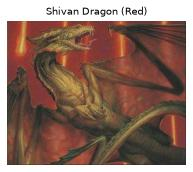

0.291  a fantasy painting of a dragon
0.230  a fantasy painting of a soldier
0.193  a fantasy painting of a forest
0.223  a fantasy painting of a machine


In [3]:
example = cards[(cards.name == "Shivan Dragon") & (cards.split == "test")].index[0]
sentences = ["a fantasy painting of a dragon", "a fantasy painting of a soldier",
             "a fantasy painting of a forest", "a fantasy painting of a machine"]
similarity = features[example] @ text_features(sentences, model, tokenizer).T

plt.figure(figsize=(3.5, 2.6))
plt.imshow(Image.open(cards.path[example]))
plt.title(f"{cards.name[example]} ({COLOR_NAMES[cards.color[example]]})", fontsize=10)
plt.axis("off")
plt.show()
for sentence, value in zip(sentences, similarity):
    print(f"{value:.3f}  {sentence}")

## 3. Hand-written prompts, and prompts from the cards' own subtypes

Several prompts for one class are averaged into one feature.
Multicolor is the odd one: it is a rule of the game, not a look. We give it our best guess, and section 5 also
reports a score on the five single colors only.

In [4]:
naive_prompts = {
    "W": ["a white Magic: The Gathering card"],
    "U": ["a blue Magic: The Gathering card"],
    "B": ["a black Magic: The Gathering card"],
    "R": ["a red Magic: The Gathering card"],
    "G": ["a green Magic: The Gathering card"],
    "Colorless": ["a colorless Magic: The Gathering card"],
    "Multicolor": ["a multicolor Magic: The Gathering card"],
}

palette_prompts = {
    "W": ["a painting in bright white and pale gold tones"],
    "U": ["a painting in cool blue tones"],
    "B": ["a dark painting in black and grey tones"],
    "R": ["a painting in warm red and orange tones"],
    "G": ["a painting in green tones"],
    "Colorless": ["a painting in grey and brown metallic tones"],
    "Multicolor": ["a painting with many different bright colors"],
}

content_subjects = {
    "W": ["angels", "knights", "soldiers", "a cleric healing", "open plains", "a cathedral"],
    "U": ["a wizard", "the sea", "an island", "a sea creature", "birds in the sky", "an illusion"],
    "B": ["zombies", "skeletons", "a swamp", "a demon", "a vampire", "death"],
    "R": ["fire", "goblins", "a dragon", "mountains", "lightning", "a volcano"],
    "G": ["a forest", "a huge beast", "elves", "giant trees", "wolves", "a druid"],
    "Colorless": ["a machine", "a metal artifact", "a golem", "an ancient relic", "a weapon"],
    "Multicolor": ["a legendary hero", "a guild leader", "a creature that is two things at once"],
}
content_prompts = {}
for color in COLOR_CLASSES:
    content_prompts[color] = [f"a fantasy painting of {subject}" for subject in content_subjects[color]]

The hand-written content list is short: six subjects per color from memory. A red card showing a minotaur or a shaman
has nothing in it pointing at Red. So a second, fuller content set takes the subjects from the game itself.

Every card's type line names what is on it ("Creature — **Goblin Warrior**", "Artifact — **Equipment**").
For each color we take the 20 subtypes that are most typical for it among the **training** cards
(share of that color's cards with the subtype, minus the share among all other cards).

This is the game's lore, read from card text. It is only used to write the description of each class, once,
from training cards. A test card is still judged from its picture alone, never from its own type line.

In [5]:
def subtypes(type_line):
    # "Legendary Creature — Goblin Warrior" -> ["Goblin", "Warrior"]
    parts = type_line.split("—")
    if len(parts) < 2:
        return []
    return parts[1].split()

train_cards = cards[is_train]
rows = []
for color, type_line in zip(train_cards.color, train_cards.type_line):
    for subtype in set(subtypes(type_line)):
        rows.append({"color": color, "subtype": subtype})
subtype_counts = pd.crosstab(pd.DataFrame(rows).subtype, pd.DataFrame(rows).color).reindex(columns=COLOR_CLASSES, fill_value=0)
cards_per_color = train_cards.color.value_counts()

subtype_prompts = {}
for color in COLOR_CLASSES:
    share_inside = subtype_counts[color] / cards_per_color[color]
    share_outside = (subtype_counts.sum(axis=1) - subtype_counts[color]) / (len(train_cards) - cards_per_color[color])
    typical = (share_inside - share_outside).sort_values(ascending=False).index[:20]
    subtype_prompts[color] = [f"a fantasy painting of a {subtype.lower()}" for subtype in typical]
    print(f"{COLOR_NAMES[color]:10s} {', '.join(typical)}")

White      Human, Soldier, Cleric, Angel, Knight, Cat, Bird, Spirit, Aura, Kor, Rebel, Griffin, Dwarf, Hero, Ally, Kithkin, Monk, Advisor, Elephant, Samurai
Blue       Wizard, Merfolk, Aura, Illusion, Bird, Rogue, Drake, Faerie, Shapeshifter, Sphinx, Vedalken, Artificer, Serpent, Pirate, Scientist, Fish, Spirit, Crab, Octopus, Djinn
Black      Zombie, Vampire, Demon, Horror, Rogue, Phyrexian, Assassin, Warlock, Rat, Skeleton, Villain, Cleric, Aura, Shade, Minion, Bat, Insect, Imp, Nightmare, Liliana
Red        Goblin, Warrior, Dragon, Shaman, Elemental, Berserker, Dwarf, Ogre, Lizard, Minotaur, Giant, Barbarian, Devil, Pirate, Phoenix, Werewolf, Orc, Cyclops, Arcane, Kavu
Green      Elf, Druid, Beast, Insect, Warrior, Snake, Plant, Shaman, Scout, Treefolk, Spider, Wurm, Dinosaur, Elemental, Fungus, Hydra, Wolf, Centaur, Bear, Dryad
Colorless  Equipment, Construct, Golem, Eldrazi, Vehicle, Scarecrow, Myr, Urza's, Book, Desert, Juggernaut, Robot, Spacecraft, Thopter, Assembly-Worker, Kar

In [6]:
all_prompts = {"naive": naive_prompts, "palette": palette_prompts,
               "content (hand-written)": content_prompts, "content (card subtypes)": subtype_prompts}

# every prompt that goes to CLIP, for Red as the example
for name in all_prompts:
    print(f"{name}:")
    for sentence in all_prompts[name]["R"]:
        print("   ", sentence)

class_text = {}
for name in all_prompts:
    class_text[name] = class_features(all_prompts[name], COLOR_CLASSES, model, tokenizer)
print({name: value.shape for name, value in class_text.items()})

naive:
    a red Magic: The Gathering card
palette:
    a painting in warm red and orange tones
content (hand-written):
    a fantasy painting of fire
    a fantasy painting of goblins
    a fantasy painting of a dragon
    a fantasy painting of mountains
    a fantasy painting of lightning
    a fantasy painting of a volcano
content (card subtypes):
    a fantasy painting of a goblin
    a fantasy painting of a warrior
    a fantasy painting of a dragon
    a fantasy painting of a shaman
    a fantasy painting of a elemental
    a fantasy painting of a berserker
    a fantasy painting of a dwarf
    a fantasy painting of a ogre
    a fantasy painting of a lizard
    a fantasy painting of a minotaur
    a fantasy painting of a giant
    a fantasy painting of a barbarian
    a fantasy painting of a devil
    a fantasy painting of a pirate
    a fantasy painting of a phoenix
    a fantasy painting of a werewolf
    a fantasy painting of a orc
    a fantasy painting of a cyclops
    a fan

## 4. Discovered words: letting the art name its own themes

Both content sets above come from knowing the game. To test content **without** any guidance:

1. Take a neutral list of 13,000 ordinary English words (from CLIP's own vocabulary and a dictionary; nothing chosen
   with Magic in mind; it includes color words like "red" as well as things like "dragon").
2. For every word, measure how well "a painting of <word>" fits the **training** pictures of each color.
3. For each color keep the words that fit its pictures much better than the other colors' pictures.

The words are found from the training set and its labels, then tested on the held-out sets.
So this is not label-free (section 7 is), but no person picked the words.

In [7]:
words, all_word_features = word_features(model, tokenizer)
print(f"{len(words):,} words, for example: {words[1000:1010]}")

found = discover_words(features[is_train], cards.color[is_train], COLOR_CLASSES, words, all_word_features, how_many=30)
for color in COLOR_CLASSES:
    print(f"{COLOR_NAMES[color]:10s} {', '.join(found[color])}")

13,098 words, for example: ['chain', 'champion', 'host', 'finish', 'delicious', 'mountain', 'register', 'recent', 'female', 'booth']
White      moors, cavalry, crusade, conquering, hurling, archery, confirmation, mercy, napoleon, soaring, sultan, angelic, leighton, recruiting, beige, honor, dove, dressage, sienna, whites, regency, suffrage, hidalgo, victory, regiment, singh, gold, soleil, crusader, triumphant
Blue       dory, aqua, underwater, blue, turquoise, azure, blues, mackerel, sonata, aquatic, jellyfish, bluebird, amarine, freeze, ocean, iceberg, dolphin, antarctica, icy, antarctic, colder, aquarium, frozen, whale, mermaid, swimming, diver, frosted, aquaculture, indigo
Black      venom, carnage, slender, slipknot, ghoul, zombie, undead, reap, lich, nightmare, vampire, undertaker, joker, mimic, hag, scarecrow, creepy, bummed, haunt, toxin, void, lobo, creep, possessed, sinister, horror, exorcist, stalker, werewolf, reaper
Red        lava, inferno, molten, eruption, carnage, fireb

**Finding:** nobody told the model the color pie, and it came back with one.
- **Black and White are described by content:** ghoul, zombie, undead, vampire, reaper; cavalry, crusade, angelic, regiment, victory.
- **Red is content that is also a palette:** lava, inferno, fireball, volcano, wildfire.
- **Blue and Green mix both:** literal color words (blue, turquoise, azure; green, greenery) next to content
  (underwater, jellyfish, whale, iceberg; forest, jungle, foliage, wildlife).
- **Colorless is machines:** machinery, spaceship, telescope, mechanism, apparatus. The histogram could not find this class at all.
- **Multicolor is cities:** avenue, cityscape, plaza, harbor, palace. That is the setting of the multicolor-heavy sets
  (a city world), not a "look" of many colors. It is a quirk of which sets contain multicolor cards.

Most of the words are places, substances and moods. Very few are creature names.
The list is unfiltered, so some noise shows up (names, word fragments).

How many words per class? Checked on the **validation** set.

In [8]:
best_count = None
best_accuracy = 0
for how_many in (1, 5, 15, 50, 150, 500, 1500):
    found_try = discover_words(features[is_train], cards.color[is_train], COLOR_CLASSES, words, all_word_features, how_many)
    text_try = np.stack([features_of_words(found_try[color], words, all_word_features) for color in COLOR_CLASSES])
    result = score(cards.color[is_val], zero_shot(features[is_val], text_try), COLOR_CLASSES)
    print(f"{how_many:4d} words per class   val accuracy {result['accuracy']:.3f}   macro-F1 {result['macro-F1']:.3f}")
    if result["accuracy"] > best_accuracy:
        best_accuracy = result["accuracy"]
        best_count = how_many

found = discover_words(features[is_train], cards.color[is_train], COLOR_CLASSES, words, all_word_features, best_count)
class_text["content (discovered)"] = np.stack([features_of_words(found[color], words, all_word_features)
                                               for color in COLOR_CLASSES])
print("using", best_count, "words per class")

   1 words per class   val accuracy 0.313   macro-F1 0.307
   5 words per class   val accuracy 0.349   macro-F1 0.334
  15 words per class   val accuracy 0.348   macro-F1 0.332
  50 words per class   val accuracy 0.358   macro-F1 0.337
 150 words per class   val accuracy 0.370   macro-F1 0.347
 500 words per class   val accuracy 0.353   macro-F1 0.330
1500 words per class   val accuracy 0.326   macro-F1 0.310
using 150 words per class


## 5. Results for color

Two scores per prompt set, both on the test sets:
- **7 classes:** the full task, comparable with notebook 03.
- **5 colors only:** only the single-color test cards, choosing between the five colors. This removes the two
  classes that are rules of the game (Multicolor, Colorless) and shows the signal for the colors themselves.

In [9]:
five = COLOR_CLASSES[:5]
is_five = is_test & cards.color.isin(five).to_numpy()

rows = [{"model": "always Multicolor", "accuracy": 0.202, "macro-F1": 0.048},
        {"model": "color histogram (notebook 03)", "accuracy": 0.340, "macro-F1": 0.304, "top-2": 0.542}]
test_probabilities = {}
for name, text in class_text.items():
    test_probabilities[name] = zero_shot(features[is_test], text)
    seven = score(cards.color[is_test], test_probabilities[name], COLOR_CLASSES)
    only_five = score(cards.color[is_five], zero_shot(features[is_five], text[:5]), five)
    rows.append({"model": f"CLIP zero-shot, {name}", **seven, "5 colors: accuracy": only_five["accuracy"]})
results = pd.DataFrame(rows).set_index("model")

# the histogram on the same 5-color question, for a fair comparison (same model as notebook 03, 5 classes)
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
thumbs, sizes = load_thumbnails(load_cards())
thumbs = thumbs[~load_cards().is_junk.to_numpy()]
histogram = color_histogram(thumbs, bins=4)
train_five = is_train & cards.color.isin(five).to_numpy()
scaler = StandardScaler().fit(histogram[train_five])
histogram_model = LogisticRegression(max_iter=300).fit(scaler.transform(histogram[train_five]), cards.color[train_five])
histogram_five = score(cards.color[is_five], histogram_model.predict_proba(scaler.transform(histogram[is_five])),
                       histogram_model.classes_)
results.loc["color histogram (notebook 03)", "5 colors: accuracy"] = histogram_five["accuracy"]
print(f"single-color test cards: {is_five.sum():,}   (chance on 5 colors: 0.200)")
results.round(3)

single-color test cards: 2,438   (chance on 5 colors: 0.200)


,accuracy,macro-F1,top-2,5 colors: accuracy
model,,,,
always Multicolor,0.202,0.048,NaN,NaN
color histogram (notebook 03),0.340,0.304,0.542,0.481
"CLIP zero-shot, naive",0.313,0.297,0.540,0.473
"CLIP zero-shot, palette",0.324,0.307,0.534,0.484
"CLIP zero-shot, content (hand-written)",0.279,0.280,0.469,0.453
"CLIP zero-shot, content (card subtypes)",0.242,0.238,0.446,0.437
"CLIP zero-shot, content (discovered)",0.362,0.335,0.535,0.499


**Finding:**
- **Discovered words are the best prompts: 36.2%.** They are the only zero-shot set above the color histogram (34.0%),
  and no classifier was trained. 150 words per class work best: 5 are too narrow, 1,500 water it down.
- **More guidance made it worse.** Order: discovered > palette, naive > hand-written content > card subtypes.
  The subtype set, the game's own lore, scored lowest (24.2%).
- **Why lore loses:** subtypes name creatures (human, warrior, wizard, rogue), and many of those live in several
  colors. Most pictures of a color also do not show its signature creature. The discovered words describe settings,
  substances and moods (lava, underwater, forest, machinery), and those are in most pictures.
- **So the content that marks a color is mostly "where and what mood", less "who is in the picture".**
- **Palette prompts (32.4%) land next to the histogram (34.0%):** CLIP can read a palette from words too.
- **On the five colors alone everything is close** (44% to 50%; discovered 49.9%, histogram 48.1%).
  Most of the 7-class gain comes from Black and Colorless (next section).

Zero-shot content beats the palette, but only by about 2 points. That is a hint, not yet proof that content carries
more than palette. The next notebook trains on these features, which is the real test.

**Decision:** the discovered set is the zero-shot model for the comparisons below.

## 6. Where CLIP beats the palette, and where not

Per class and per era, for the best prompt set against the histogram numbers from notebook 03.

best prompt set: content (discovered)


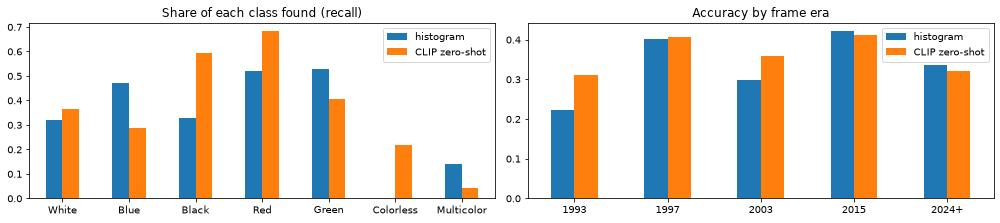

                White  Blue  Black   Red  Green  Colorless  Multicolor
histogram        0.32  0.47   0.33  0.52   0.53       0.00        0.14
CLIP zero-shot   0.37  0.29   0.59  0.68   0.41       0.22        0.04

                 1993   1997   2003   2015  2024+
histogram       0.224  0.402  0.298  0.421  0.336
CLIP zero-shot  0.311  0.408  0.358  0.412  0.321


In [10]:
zero_shot_names = [name for name in results.index if name.startswith("CLIP")]
best_name = results.loc[zero_shot_names, "accuracy"].idxmax().replace("CLIP zero-shot, ", "")
best = test_probabilities[best_name]
predicted = np.array(COLOR_CLASSES)[best.argmax(axis=1)]
test_cards = cards[is_test]
print("best prompt set:", best_name)

recall = pd.DataFrame({
    "histogram": [0.32, 0.47, 0.33, 0.52, 0.53, 0.00, 0.14],     # from notebook 03
    "CLIP zero-shot": confusion_matrix(test_cards.color, predicted, labels=COLOR_CLASSES, normalize="true").diagonal(),
}, index=[COLOR_NAMES[c] for c in COLOR_CLASSES])

rows = []
for era in ["1993", "1997", "2003", "2015", "2024+"]:
    in_era = (test_cards.era == era).to_numpy()
    rows.append(score(test_cards.color[in_era], best[in_era], COLOR_CLASSES)["accuracy"])
by_era = pd.DataFrame({"histogram": [0.224, 0.402, 0.298, 0.421, 0.336],   # from notebook 03
                       "CLIP zero-shot": rows}, index=["1993", "1997", "2003", "2015", "2024+"])

fig, axes = plt.subplots(1, 2, figsize=(14, 3.2))
recall.plot.bar(ax=axes[0], rot=0, title="Share of each class found (recall)")
by_era.plot.bar(ax=axes[1], rot=0, title="Accuracy by frame era")
plt.tight_layout()
plt.show()
print(recall.round(2).T.to_string())
print()
print(by_era.round(3).T.to_string())

**Finding:** the two models are good at different classes.
- **CLIP is far better where the subject is distinctive:** Black 59% vs 33%, Red 68% vs 52%, Colorless 22% vs 0%.
- **The palette is better where the paint color is the cue:** Blue 47% vs 29%, Green 53% vs 41%.
- **Multicolor stays unsolved** (4% and 14%).
- **CLIP is steadier across time:** 31% to 41% in every era. On the 1993-era sets, where the palette model fell to
  22%, CLIP holds 31%. A zombie is a zombie in 1994 and in 2024; the paint colors changed.

Because they make different mistakes, a model that uses both cues should beat either one.

## 7. No labels at all: do the colors show up as groups?

The fully unguided test. **K-means** sorts the training pictures into groups of similar pictures without seeing any
label. Afterwards we check how well the groups line up with the colors:

- **NMI** (normalized mutual information): 0 = groups have nothing to do with color, 1 = groups are the colors.
- **Accuracy:** name each group after its most common color (the only use of labels), then use that on the test sets.

Done once with CLIP features (content and look) and once with the color histogram (palette only).

In [11]:
histogram_scaled = StandardScaler().fit(histogram[is_train]).transform(histogram)

rows = []
for feature_name, x in (("color histogram", histogram_scaled), ("CLIP", features)):
    for groups in (7, 50):
        kmeans = KMeans(n_clusters=groups, n_init=3, random_state=0).fit(x[is_train])
        train_groups = kmeans.labels_
        # name each group after its most common color in the training set
        table = pd.crosstab(train_groups, cards.color[is_train].to_numpy())
        group_color = table.idxmax(axis=1)
        test_guess = group_color[kmeans.predict(x[is_test])].to_numpy()
        rows.append({"features": feature_name, "groups": groups,
                     "NMI": normalized_mutual_info_score(cards.color[is_train], train_groups),
                     "test accuracy": (test_guess == cards.color[is_test].to_numpy()).mean()})
        if feature_name == "CLIP" and groups == 50:
            clip_kmeans = kmeans
            clip_table = table
pd.DataFrame(rows).set_index(["features", "groups"]).round(3)

NMI  test accuracy
features        groups                      
color histogram 7       0.052          0.262
                50      0.052          0.307
CLIP            7       0.031          0.233
                50      0.063          0.292

In [12]:
# what are the CLIP groups? the neutral words closest to each group's center, for the 8 most one-colored groups
share = clip_table.div(clip_table.sum(axis=1), axis=0)
most_pure = share.max(axis=1).sort_values(ascending=False).index[:8]
for group in most_pure:
    center = clip_kmeans.cluster_centers_[group]
    closest = np.argsort(-(all_word_features @ center))[:6]
    color = share.loc[group].idxmax()
    print(f"group {group:2d}: {share.loc[group].max():.0%} {COLOR_NAMES[color]:10s} "
          f"({clip_table.loc[group].sum():4d} pictures)  {', '.join(words[i] for i in closest)}")

group  5: 64% Red        ( 757 pictures)  fireball, burning, flaming, bonfire, eruption, combustion
group 20: 50% Black      ( 733 pictures)  gruesome, brutality, disturbed, crawler, brutal, undead
group 31: 50% Colorless  ( 542 pictures)  unlocking, lawful, artifact, relic, alchemy, clockwork
group 47: 49% White      ( 714 pictures)  winged, soaring, phoenix, griffin, wing, condor
group 12: 47% Blue       ( 709 pictures)  kraken, bant, leviathan, whirlwind, unleash, torrent
group 32: 46% Green      ( 689 pictures)  bant, druid, elves, hearthstone, sow, wow
group 33: 46% White      ( 531 pictures)  crusade, conquer, crusader, conquering, conquest, battle
group  6: 42% Green      ( 778 pictures)  elves, unearthed, creature, instinct, bant, encounter


**Finding:** without labels, the colors do not show up as groups, for either kind of feature (NMI at most 0.06;
test accuracy 23% to 31%, below both labeled models). Color is not what organizes the art. In CLIP's view pictures
group by subject (winged creatures, sea monsters, battles), and subjects cut across colors.

But single groups are meaningful, and the nearest words name them without any help: a fire group that is 64% Red,
an undead group 50% Black, a relic and clockwork group 50% Colorless, a winged group 49% White, a sea-monster group
47% Blue, an elves and druids group 46% Green.

So the color signal is in the features, spread over many themes. It takes labels to pull it out.

## 8. Type

Same idea for the 7 types: hand-written prompts, and discovered words.
Notebook 03 showed the palette knows nothing about type, so anything above "always Creature" (49.9% accuracy,
0.095 macro-F1) comes from content.

In [13]:
type_prompts = {
    "Creature": ["a fantasy painting of a creature", "a fantasy painting of a warrior or a monster"],
    "Planeswalker": ["a portrait of a powerful mage, the hero of the story"],
    "Land": ["a landscape painting of a place, with no people"],
    "Artifact": ["a painting of an object, a device or a machine"],
    "Enchantment": ["a painting of a magical aura surrounding someone"],
    "Instant": ["a painting of a sudden magical spell in the middle of a fight"],
    "Sorcery": ["a painting of a great ritual or a disaster"],
}
type_text = {"hand-written": class_features(type_prompts, TYPE_CLASSES, model, tokenizer)}

found_types = discover_words(features[is_train], cards.type[is_train], TYPE_CLASSES, words, all_word_features, best_count)
type_text["discovered"] = np.stack([features_of_words(found_types[t], words, all_word_features) for t in TYPE_CLASSES])
for t in TYPE_CLASSES:
    print(f"{t:13s} {', '.join(found_types[t][:12])}")

rows = [{"model": "always Creature", "accuracy": 0.499, "macro-F1": 0.095},
        {"model": "color histogram (notebook 03)", "accuracy": 0.498, "macro-F1": 0.095, "top-2": 0.608}]
type_probabilities = {}
for name, text in type_text.items():
    type_probabilities[name] = zero_shot(features[is_test], text)
    rows.append({"model": f"CLIP zero-shot, {name}", **score(cards.type[is_test], type_probabilities[name], TYPE_CLASSES)})
type_results = pd.DataFrame(rows).set_index("model")
type_results.round(3)

Creature      roach, griffin, hag, raptor, monger, cracker, rider, sneaky, butcher, congressman, auditor, noxious
Planeswalker  storm, mage, ana, nat, gal, rogue, cleric, countess, sienna, cass, kat, caster
Land          masjid, viaduct, place, landscape, architecture, mosque, barbican, surroundings, viewpoint, cityscape, geothermal, scenery
Artifact      microscope, roundabout, telescope, conception, lain, machinery, spaceship, mechanism, voyager, brooch, jellyfish, apparatus
Enchantment   synod, nativity, assumption, visitation, baptism, communion, cabaret, procession, conception, confirmation, acupuncture, ceremony
Instant       assumption, explode, backlash, sparring, visitation, impact, boiling, fighting, punching, superman, shocker, tackling
Sorcery       visitation, assumption, synod, nativity, hell, slipknot, explode, concert, sacrificing, interaction, boiling, procession


,accuracy,macro-F1,top-2
model,,,
always Creature,0.499,0.095,NaN
color histogram (notebook 03),0.498,0.095,0.608
"CLIP zero-shot, hand-written",0.384,0.252,0.552
"CLIP zero-shot, discovered",0.373,0.284,0.581


In [14]:
best_type = type_results.iloc[2:]["macro-F1"].idxmax().replace("CLIP zero-shot, ", "")
type_predicted = np.array(TYPE_CLASSES)[type_probabilities[best_type].argmax(axis=1)]
type_recall = confusion_matrix(cards.type[is_test], type_predicted, labels=TYPE_CLASSES, normalize="true").diagonal()
print("prompts:", best_type)
print(pd.Series(type_recall, index=TYPE_CLASSES).round(2).to_string())

prompts: discovered
Creature        0.47
Planeswalker    0.47
Land            0.50
Artifact        0.37
Enchantment     0.06
Instant         0.49
Sorcery         0.04


**Finding:**
- **Type is visible to CLIP with no training:** macro-F1 0.284 (discovered) and 0.252 (hand-written), against 0.095
  for the majority guess and for the histogram. Accuracy is lower than "always Creature" (37% vs 50%) only because
  the model no longer answers Creature for everything; this is why notebook 02 chose macro-F1 for type.
- **It finds about half of the lands, instants, creatures and planeswalkers,** and 37% of the artifacts.
- **Enchantment (6%) and Sorcery (4%) are nearly invisible.** The discovered words show why: Instant gets action
  words (explode, impact, fighting, punching), while Sorcery and Enchantment share the same ceremony words
  (visitation, procession, synod). They do not have a look of their own.
- For comparison, the reference project's trained CNN reached 0.286 macro-F1 on type. Zero-shot CLIP matches that
  without seeing a single label.

The palette knew nothing about type; content clearly does.

## 9. Text search

The same features give a search engine for free: type anything, get the closest pictures.
(This becomes part of the app.)

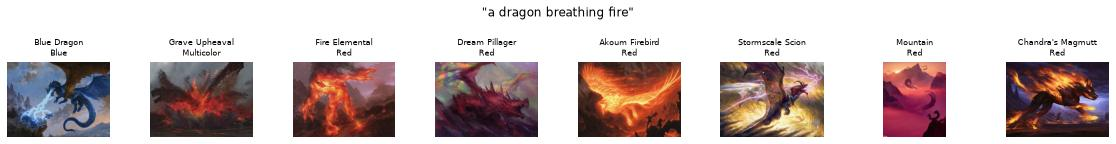

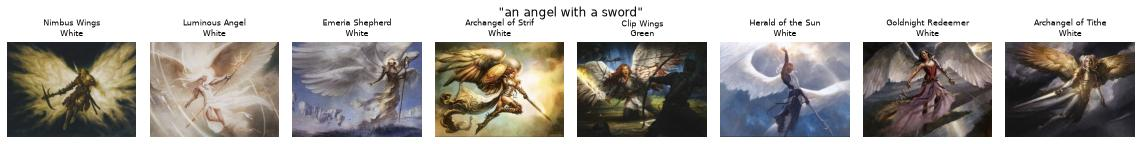

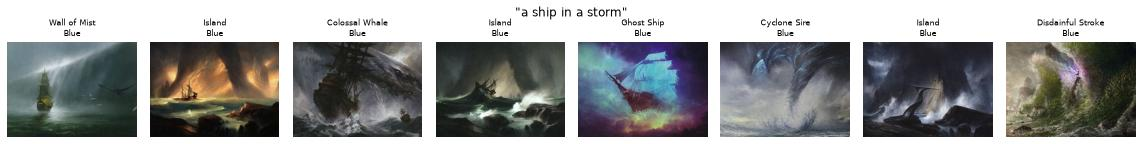

In [15]:
def search(text, how_many=8):
    query = text_features([f"a fantasy painting of {text}"], model, tokenizer)[0]
    closest = np.argsort(-(features @ query))[:how_many]
    fig, axes = plt.subplots(1, how_many, figsize=(2 * how_many, 2))
    for ax, i in zip(axes, closest):
        ax.imshow(Image.open(cards.path[i]))
        ax.set_title(f"{cards.name[i][:18]}\n{COLOR_NAMES[cards.color[i]]}", fontsize=8)
        ax.axis("off")
    plt.suptitle(f'"{text}"', fontsize=12)
    plt.tight_layout()
    plt.show()

search("a dragon breathing fire")
search("an angel with a sword")
search("a ship in a storm")

**Finding:** searching for a subject returns cards of mostly one color: "a dragon breathing fire" gives Red cards
(6 of 8), "an angel with a sword" White (7 of 8), "a ship in a storm" Blue (8 of 8). Content and color are tied
together, visible by eye.

## 10. Summary

| Test set, color (7 classes) | Accuracy | Macro-F1 | Top-2 | 5 colors only |
|---|---|---|---|---|
| Always Multicolor | 20.2% | 0.048 | | |
| Color histogram (03) | 34.0% | 0.304 | 54.2% | 48.1% |
| CLIP zero-shot, card subtypes | 24.2% | 0.238 | 44.6% | 43.7% |
| CLIP zero-shot, hand-written content | 27.9% | 0.280 | 46.9% | 45.3% |
| CLIP zero-shot, naive | 31.3% | 0.297 | 54.0% | 47.3% |
| CLIP zero-shot, palette | 32.4% | 0.307 | 53.4% | 48.4% |
| **CLIP zero-shot, discovered words** | **36.2%** | **0.335** | **53.5%** | **49.9%** |

| Test set, type (7 classes) | Accuracy | Macro-F1 |
|---|---|---|
| Always Creature | 49.9% | 0.095 |
| Color histogram (03) | 49.8% | 0.095 |
| CLIP zero-shot, hand-written | 38.4% | 0.252 |
| **CLIP zero-shot, discovered words** | 37.3% | **0.284** |

**H3 is partly supported.** CLIP does know the game's themes: left alone, it describes Black as undead, Red as fire,
Colorless as machines, and it finds types the palette cannot see. But naming the game ("a red Magic: The Gathering
card") is no better than describing a palette, and our own descriptions of the themes did worse than the words the
art chose for itself.

What this says about content versus palette:
- Content helps most for Black, Red and Colorless, and on old art.
- The palette still wins for Blue and Green.
- The content that marks a color is mostly setting and mood, not the creature in the picture.
- Zero-shot, the gain over the palette is small (36.2% vs 34.0%).

**Next:** 05 trains a classifier on these same CLIP features, and fine-tunes a ResNet18. If content really carries
more than palette, a trained model should clear the histogram by a wide margin.
